# 1 · IEG ("plasticity") score: compute it and partition it by cell type

Per-neuron rapid-IEG score in the mouse M1 Patch-seq dataset (Scala et al. 2021, GEO GSE163764), and the share of
its variance explained by transcriptomic type. Needs the M1 Patch-seq files (`uv run python data/fetch_data.py`).

In [1]:
import sys, pathlib
HERE = pathlib.Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "analysis" / "common").exists())
sys.path.insert(0, str(ROOT / "analysis" / "common"))
import numpy as np, pandas as pd, scanpy as sc, anndata as ad, matplotlib.pyplot as plt
from common import PATCHSEQ_DIR, GENE_SETS
sc.settings.verbosity = 0

## Load counts (exon + intron) and metadata, apply QC

In [2]:
exon = pd.read_csv(PATCHSEQ_DIR / "GSE163764_m1_patchseq_exon_counts.csv", index_col=0)
intron = pd.read_csv(PATCHSEQ_DIR / "GSE163764_m1_patchseq_intron_counts.csv", index_col=0).reindex_like(exon).fillna(0)
meta = pd.read_csv(PATCHSEQ_DIR / "m1_patchseq_meta_data.csv", sep="\t").set_index("Cell")
counts = (exon + intron).T
cells = counts.index.intersection(meta.index)
a = ad.AnnData(counts.loc[cells].values.astype(np.float32), obs=meta.loc[cells].copy(),
               var=pd.DataFrame(index=counts.columns))
a.obs["n_genes"] = (a.X > 0).sum(1)
keep = (a.obs["RNA family"] != "low quality") & a.obs["Exclusion reasons"].isna() & (a.obs["n_genes"] >= 1000)
a = a[keep.values].copy()
sc.pp.normalize_total(a, target_sum=1e6); sc.pp.log1p(a)
print(a.n_obs, "cells,", a.obs["RNA type"].nunique(), "t-types")

1227 cells, 77 t-types


## The score
Mean expression of the 19 rapid IEGs minus the mean of 100 expression-matched control genes per cell
(`scanpy.tl.score_genes`). Matching the controls on expression removes sequencing-depth effects that a plain
average of z-scores would pick up.

['Fos', 'Fosb', 'Junb', 'Jun', 'Egr1', 'Egr2', 'Egr3', 'Egr4', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Nr4a3', 'Ier2', 'Dusp1', 'Dusp6', 'Btg2', 'Klf4', 'Atf3']


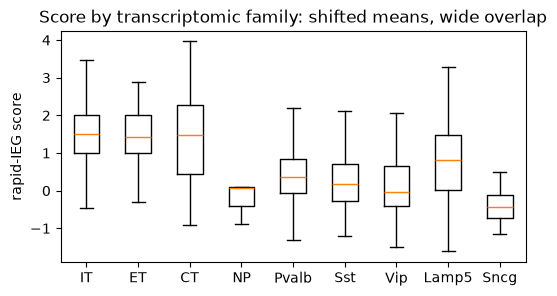

In [3]:
print(GENE_SETS["IEG_rapid"])
sc.tl.score_genes(a, GENE_SETS["IEG_rapid"], score_name="ieg_score", ctrl_size=100, n_bins=25, random_state=0)
fam_order = ["IT", "ET", "CT", "NP", "Pvalb", "Sst", "Vip", "Lamp5", "Sncg"]
fig, ax = plt.subplots(figsize=(6, 3))
data = [a.obs.loc[a.obs["RNA family"] == f, "ieg_score"] for f in fam_order]
ax.boxplot(data, tick_labels=fam_order, showfliers=False); ax.set_ylabel("rapid-IEG score")
ax.set_title("Score by transcriptomic family: shifted means, wide overlap"); plt.show()

## Variance explained by t-type
Adjusted R² of the score on t-type, separately in excitatory and inhibitory neurons.

In [4]:
import statsmodels.formula.api as smf
a.obs["family"] = a.obs["RNA family"].astype(str)
a.obs["cls"] = np.where(a.obs["family"].isin(["IT", "ET", "CT", "NP"]), "glutamatergic", "GABAergic")
for cl, g in a.obs.groupby("cls"):
    g = g.assign(ttype=g["RNA type"].astype(str))
    r2 = smf.ols("ieg_score ~ C(ttype)", g).fit().rsquared_adj
    print(f"{cl:14s} n={len(g):4d}  variance explained by t-type: {r2:.2f}  ->  within-type: {1 - r2:.2f}")

GABAergic      n= 817  variance explained by t-type: 0.17  ->  within-type: 0.83
glutamatergic  n= 410  variance explained by t-type: 0.10  ->  within-type: 0.90
